# 01 — Exploration, nettoyage et split

Objectif : comprendre le dataset **avant toute modélisation**, nettoyer les énoncés et figer un découpage
train / val / test **sans fuite de données**.

1. Vue d'ensemble (schéma, valeurs manquantes, colonnes constantes)
2. Unicité, quasi-doublons et risques de fuite
3. Distribution des labels (multi-label, déséquilibre, co-occurrences)
4. Longueur des textes et du code, difficulté
5. Nettoyage (`4 982 → 4 834` exemples) et split stratifié multi-label

**Sortie** : `data/processed/clean.parquet`, relu par les notebooks 02 à 04.

In [1]:
import json
import re
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from langdetect import DetectorFactory, LangDetectException, detect
from nltk.stem import WordNetLemmatizer
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)

## Paramètres

Tous les choix du notebook sont regroupés ici.

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks_prod" else Path.cwd()
RAW_DIR = ROOT / "data" / "code_classification_dataset"
OUTPUT_PATH = ROOT / "data" / "processed" / "clean.parquet"
GDRIVE_ID = "1FyNPiEKkZBfhz4ua0eM3PQjbRWVwO95J"  # archive fournie par le sujet

TAGS = ["math", "graphs", "strings", "number theory", "trees", "geometry", "games", "probabilities"]
SEED = 42
NEAR_DUP_THRESHOLD = 0.8  # au-delà, les paires inspectées sont des variantes d'un même énoncé (section 2)
VAL_SIZE, TEST_SIZE = 0.15, 0.15

## Chargement

Un fichier `sample_<id>.json` par exercice. On garde l'identifiant du fichier comme index (`sample_id`).

In [3]:
if not RAW_DIR.exists():
    import zipfile

    import gdown  # seulement utile au premier lancement

    archive = ROOT / "data" / "dataset.zip"
    archive.parent.mkdir(parents=True, exist_ok=True)
    gdown.download(id=GDRIVE_ID, output=str(archive), quiet=True)
    zipfile.ZipFile(archive).extractall(archive.parent)
    archive.unlink()

files = sorted(RAW_DIR.glob("sample_*.json"), key=lambda p: int(p.stem.split("_")[1]))
raw = pd.DataFrame(
    [json.loads(p.read_text()) for p in files],
    index=pd.Index([int(p.stem.split("_")[1]) for p in files], name="sample_id"),
)
print(f"Dataset brut : {raw.shape}")
raw.head(3)

Dataset brut : (4982, 21)


,prob_desc_time_limit,prob_desc_sample_outputs,src_uid,prob_desc_notes,prob_desc_description,prob_desc_output_spec,prob_desc_input_spec,prob_desc_output_to,prob_desc_input_from,lang,...,difficulty,file_name,code_uid,prob_desc_memory_limit,prob_desc_sample_inputs,exec_outcome,source_code,prob_desc_created_at,tags,hidden_unit_tests
sample_id,,,,,,,,,,,,,,,,,,,,,
0,2 seconds,"[""2\n2 4\n3 3\n3 1""]",591372383cf3624f69793c41370022de,None,"Numbers $$$1, 2, 3, \dots n$$$ (each integer from $$$1$$$ to $$$n$$$ once) are written on a board. In one operation ...","For each test case, in the first line, print the minimum possible number left on the board after $$$n - 1$$$ operati...",The first line contains one integer $$$t$$$ ($$$1 \le t \le 1000$$$) — the number of test cases. The only line of ea...,standard output,standard input,Python 3,...,1000.0,train_000.jsonl,88084dde61bbebdebe163309a2bda179,256 megabytes,"[""1\n4""]",PASSED,"\ndef ii(): return int(input())\ndef mi(): return map(int, input().split())\n\n\nif __name__ == '__main__':\n for...",1602407100,"[greedy, constructive algorithms, math, implementation, data structures]",
1,3 seconds,"[""4\n10\n4\n0""]",afcd41492158e68095b01ff1e88c3dd4,"NoteIn the first test case of the example, the optimal sequence of moves can be as follows: before making moves $$$...","There are $$$n$$$ positive integers $$$a_1, a_2, \dots, a_n$$$. For the one move you can choose any even value $$$c$...",For $$$t$$$ test cases print the answers in the order of test cases in the input. The answer for the test case is th...,The first line of the input contains one integer $$$t$$$ ($$$1 \le t \le 10^4$$$) — the number of test cases in the ...,standard output,standard input,Python 3,...,1200.0,train_000.jsonl,df0e2ae03513f2b9280e19a1df6c8d84,256 megabytes,"[""4\n6\n40 6 40 3 20 1\n1\n1024\n4\n2 4 8 16\n3\n3 1 7""]",PASSED,"a = int(input())\nfor i in range(a):\n f = int(input())\n k = list(map(int, input().split()))\n l = set()\n...",1576321500,"[number theory, greedy]",
2,2 seconds,"[""0\n1\n2\n0""]",d0c50562764f2008045fe57e5da5de1c,None,You are playing a game where your character should overcome different obstacles. The current problem is to come down...,For each query print one integer — the minimum number of magic crystals you have to spend to safely come down on the...,The first line contains one integer $$$q$$$ ($$$1 \le q \le 100$$$) — the number of queries. Each query contains two...,standard output,standard input,PyPy 2,...,1600.0,train_000.jsonl,b084f1988c923dff4a8b4fa95dc6f846,256 megabytes,"[""4\n3 2\n3 1\n8 6\n8 7 6 5 3 2\n9 6\n9 8 5 4 3 1\n1 1\n1""]",PASSED,"#!/usr/bin/env pypy\nfrom __future__ import division, print_function\nfrom collections import defaultdict, Counter, ...",1570545300,"[dp, greedy, math]",


## 1. Vue d'ensemble du schéma

In [4]:
overview = pd.DataFrame(
    {
        "dtype": raw.dtypes.astype(str),
        "n_missing": raw.isna().sum(),
        "pct_missing": (raw.isna().mean() * 100).round(1),
        "n_unique": raw.apply(lambda s: s.astype(str).nunique()),
    }
).sort_values("n_missing", ascending=False)
overview

,dtype,n_missing,pct_missing,n_unique
prob_desc_notes,object,1350,27.1,3597
prob_desc_output_spec,object,85,1.7,4822
difficulty,float64,39,0.8,30
prob_desc_input_spec,object,33,0.7,4928
prob_desc_output_to,object,1,0.0,4
prob_desc_input_from,object,1,0.0,4
prob_desc_time_limit,object,0,0.0,22
prob_desc_memory_limit,object,0,0.0,17
tags,object,0,0.0,1907
prob_desc_created_at,object,0,0.0,1156


In [5]:
# Colonnes constantes ou vides : aucune information exploitable
constant_cols = [c for c in raw.columns if raw[c].astype(str).nunique() <= 1]
print("Colonnes constantes :", constant_cols)

for col in ["lang", "prob_desc_input_from", "prob_desc_memory_limit"]:
    print(f"\n--- {col} ---")
    print(raw[col].value_counts(dropna=False).head(6))

Colonnes constantes : ['lang_cluster', 'exec_outcome', 'hidden_unit_tests']

--- lang ---
lang
Python 3     2089
PyPy 3        935
PyPy 3-64     716
PyPy 2        654
Python 2      588
Name: count, dtype: int64

--- prob_desc_input_from ---
prob_desc_input_from
standard input      4933
input.txt             32
стандартный ввод      16
None                   1
Name: count, dtype: int64

--- prob_desc_memory_limit ---
prob_desc_memory_limit
256 megabytes     4521
512 megabytes      347
64 megabytes        61
1024 megabytes      15
256 мегабайт        12
128 megabytes        9
Name: count, dtype: int64


**Constats sur le schéma**
- **4 982 exercices**, 21 colonnes ; `lang_cluster`, `exec_outcome` (constantes) et `hidden_unit_tests` (vide) sont inutilisables.
- `prob_desc_notes` manque dans **27 %** des cas, `difficulty` dans 39 cas, `prob_desc_input_spec` dans 33 cas.
- Quelques métadonnées sont en **russe** (`стандартный ввод`, `мегабайт`) : il faudra vérifier la langue des énoncés.
- `lang` mélange **Python 2 et Python 3** : un parsing `ast` Python 3 échouerait sur une partie des solutions,
  on traitera donc le code comme du texte (tokens, encodeur pré-entraîné sur du code).

## 2. Unicité, quasi-doublons et risques de fuite

Le sujet annonce des exercices tous différents. On vérifie les doublons exacts, puis les **quasi-doublons**
(variantes *easy / hard* d'un même énoncé) : répartis entre train et test, ils gonfleraient artificiellement les scores.

In [6]:
for col in ["src_uid", "prob_desc_description", "source_code"]:
    print(f"{col:<25} uniques : {raw[col].nunique()} / {len(raw)}")

src_uid                   uniques : 4982 / 4982
prob_desc_description     uniques : 4982 / 4982
source_code               uniques : 4982 / 4982


,seuil,n_paires
0,0.6,794
1,0.7,266
2,0.8,116
3,0.9,75


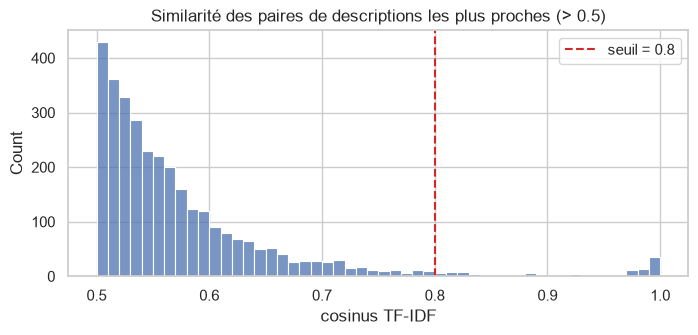

In [7]:
def similar_pairs(texts: pd.Series, threshold: float, **tfidf_kwargs) -> pd.DataFrame:
    """Paires (i, j) dont la similarité cosinus TF-IDF dépasse `threshold`."""
    X = TfidfVectorizer(**tfidf_kwargs).fit_transform(texts)
    sim = cosine_similarity(X)
    np.fill_diagonal(sim, 0)
    i, j = np.where(np.triu(sim) > threshold)
    return pd.DataFrame({"i": texts.index[i], "j": texts.index[j], "sim": sim[i, j]})


desc_pairs = similar_pairs(raw["prob_desc_description"], threshold=0.5, min_df=2)
display(pd.DataFrame({"seuil": [0.6, 0.7, 0.8, 0.9], "n_paires": [(desc_pairs["sim"] > t).sum() for t in [0.6, 0.7, 0.8, 0.9]]}))

fig, ax = plt.subplots(figsize=(8, 3.2))
sns.histplot(desc_pairs["sim"], bins=50, ax=ax)
ax.axvline(NEAR_DUP_THRESHOLD, color="tab:red", linestyle="--", label=f"seuil = {NEAR_DUP_THRESHOLD}")
ax.set(title="Similarité des paires de descriptions les plus proches (> 0.5)", xlabel="cosinus TF-IDF")
ax.legend()
plt.show()

In [8]:
# Les paires au-dessus du seuil ont-elles les mêmes tags ?
pairs = desc_pairs[desc_pairs["sim"] > NEAR_DUP_THRESHOLD]
target_tags = raw["tags"].apply(lambda ts: set(ts) & set(TAGS))
same_tags = [set(raw.at[i, "tags"]) == set(raw.at[j, "tags"]) for i, j in zip(pairs["i"], pairs["j"])]
same_target = [target_tags[i] == target_tags[j] for i, j in zip(pairs["i"], pairs["j"])]
print(f"{len(pairs)} paires > {NEAR_DUP_THRESHOLD}")
print(f"  tags identiques (37 tags)  : {np.mean(same_tags):.0%}")
print(f"  tags cibles identiques (8) : {np.mean(same_target):.0%}")

# Même contrôle sur le code : on s'attend surtout à des templates d'entrée/sortie partagés
code_pairs = similar_pairs(raw["source_code"], threshold=0.95, min_df=2, token_pattern=r"\S+")
code_pairs = code_pairs.merge(desc_pairs, on=["i", "j"], how="left", suffixes=("", "_desc")).fillna({"sim_desc": 0})
print(f"\n{len(code_pairs)} paires de codes quasi identiques (> 0.95), dont {(code_pairs['sim_desc'] > 0.8).sum()} avec descriptions proches")

116 paires > 0.8
  tags identiques (37 tags)  : 17%
  tags cibles identiques (8) : 75%



57 paires de codes quasi identiques (> 0.95), dont 2 avec descriptions proches


In [9]:
# Une colonne contient-elle les tags en clair ? Et que vaut une recherche de mots-clés naïve ?
for col in raw.select_dtypes("object").columns.drop("tags"):
    hits = raw[col].astype(str).str.extract(r"(.{0,50}tags?\s*[:=].{0,50})", flags=re.IGNORECASE)[0].dropna()
    for k, snippet in hits.items():
        print(f"{col} [{k}] : ...{snippet}...")

KEYWORDS = {
    "math": r"\bmath",
    "graphs": r"\bgraph",
    "strings": r"\bstring",
    "number theory": r"\b(?:prime|gcd|divisor|modulo)",
    "trees": r"\btree",
    "geometry": r"\b(?:polygon|point|circle|angle)",
    "games": r"\b(?:game|player|win)",
    "probabilities": r"\b(?:probabilit|expected)",
}
desc_lower = raw["prob_desc_description"].str.lower()
rows = []
for tag, pattern in KEYWORDS.items():
    has_kw = desc_lower.str.contains(pattern)
    has_tag = pd.Series([tag in ts for ts in raw["tags"]], index=raw.index)
    rows.append({"tag": tag, "P(tag | mot-clé)": has_tag[has_kw].mean(), "P(mot-clé | tag)": has_kw[has_tag].mean()})
pd.DataFrame(rows).set_index("tag").round(2)

prob_desc_description [1098] : ...gular HTML table in which meet only the following tags : "table", "tr", "td", all the tags are paired and ...


,P(tag | mot-clé),P(mot-clé | tag)
tag,,
math,0.43,0.04
graphs,0.60,0.31
strings,0.50,0.75
number theory,0.40,0.45
trees,0.71,0.63
geometry,0.22,0.77
games,0.15,0.89
probabilities,0.69,0.68


**Constats**
- Aucun doublon exact, mais **116 paires de quasi-doublons** (cosinus > 0,8) : des variantes *easy/hard* dont les
  37 tags ne coïncident que dans 17 % des cas. Elles seront **retirées avant le split** pour éviter toute fuite.
- Les paires de codes quasi identiques viennent de **templates d'en-tête** (fast-IO, imports) sur des problèmes distincts.
- Aucune colonne ne contient la vérité terrain. `math` n'apparaît littéralement que dans **4 %** des énoncés taggés
  `math` : c'est un tag conceptuel, une recherche de mots-clés ne suffira pas.

## 3. Distribution des labels

37 tags distincts au total


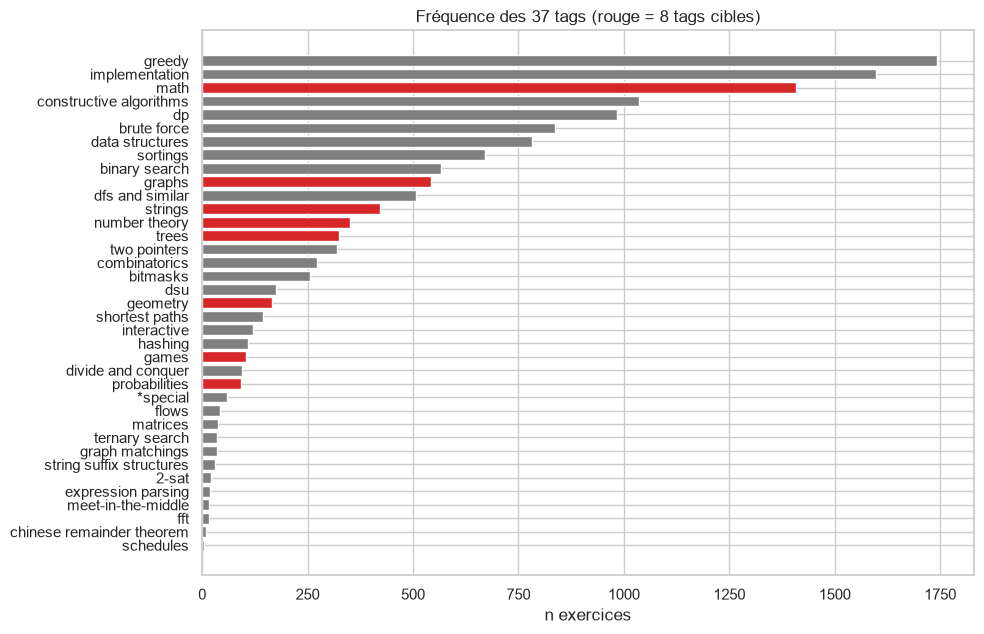

,n,prevalence_%,négatifs par positif
math,1409,28.3,2.5
graphs,542,10.9,8.2
strings,422,8.5,10.8
number theory,350,7.0,13.2
trees,324,6.5,14.4
geometry,166,3.3,29.0
games,105,2.1,46.4
probabilities,92,1.8,53.2


In [10]:
tag_counts = pd.Series(Counter(t for ts in raw["tags"] for t in ts)).sort_values(ascending=False)
print(f"{len(tag_counts)} tags distincts au total")

fig, ax = plt.subplots(figsize=(10, 6.5))
colors = ["tab:red" if t in TAGS else "tab:gray" for t in tag_counts.index]
ax.barh(tag_counts.index[::-1], tag_counts.values[::-1], color=colors[::-1])
ax.set(title="Fréquence des 37 tags (rouge = 8 tags cibles)", xlabel="n exercices")
plt.tight_layout()
plt.show()

target_stats = pd.DataFrame({"n": tag_counts[TAGS], "prevalence_%": (tag_counts[TAGS] / len(raw) * 100).round(1)})
target_stats["négatifs par positif"] = (len(raw) / target_stats["n"] - 1).round(1)
target_stats

Sans tag cible : 46.2% | nb moyen de tags cibles : 0.68


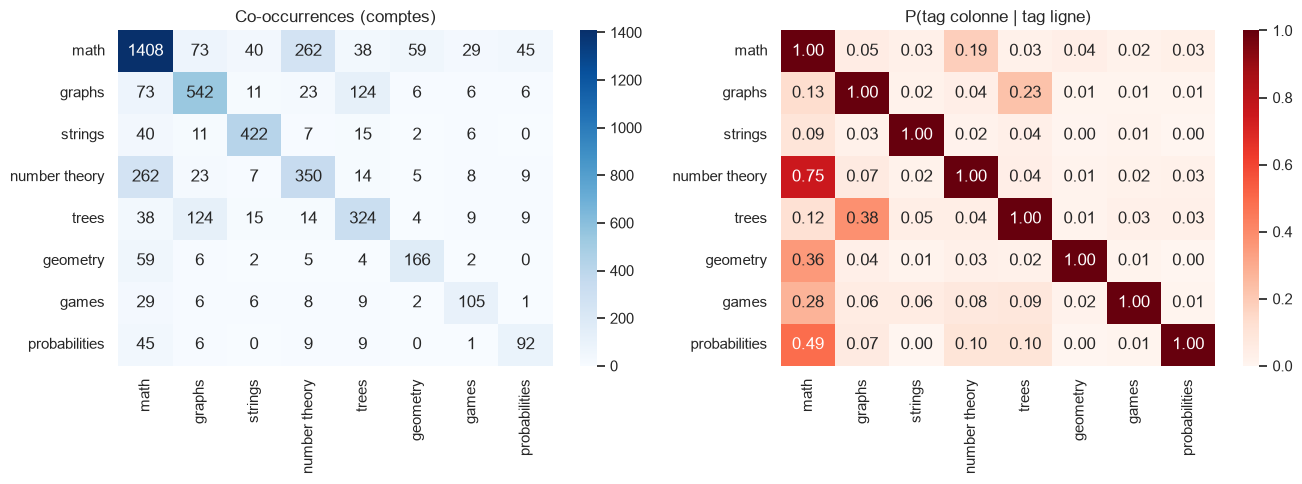

In [11]:
# Matrice binaire (n_exercices x 8) : une colonne par tag cible
Y_raw = pd.DataFrame([[tag in ts for tag in TAGS] for ts in raw["tags"]], index=raw.index, columns=TAGS).astype(int)
n_target_tags = Y_raw.sum(axis=1)
print(f"Sans tag cible : {(n_target_tags == 0).mean():.1%} | nb moyen de tags cibles : {n_target_tags.mean():.2f}")

cooc = Y_raw.T @ Y_raw
cond = cooc.div(np.diag(cooc), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
sns.heatmap(cooc, annot=True, fmt="d", cmap="Blues", ax=axes[0]).set(title="Co-occurrences (comptes)")
sns.heatmap(cond, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=axes[1]).set(title="P(tag colonne | tag ligne)")
plt.tight_layout()
plt.show()

**Constats** : 46 % des exercices n'ont aucun tag cible et la prévalence va de 28 % (`math`) à 1,8 % (`probabilities`).
On utilisera donc des métriques **macro** (chaque tag compte autant), des classes pondérées et un **seuil de
décision par tag**. `trees` co-occurre fortement avec `graphs`, `number theory` avec `math`.

## 4. Longueur des textes, du code et difficulté

,count,mean,std,min,25%,50%,75%,max
mots (description),4982.0,167.0,80.0,10.0,110.0,155.0,211.0,684.0
lignes de code,4982.0,52.0,79.0,1.0,18.0,33.0,59.0,2042.0


math             27.0
games            28.0
strings          30.0
geometry         34.0
number theory    38.0
probabilities    41.0
graphs           55.0
trees            61.0

difficulty : 39 NaN, 15 valeurs à -1 (sentinelle)


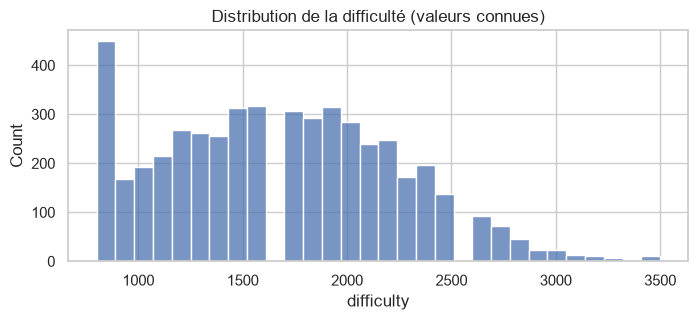

In [12]:
lengths = pd.DataFrame(
    {
        "mots (description)": raw["prob_desc_description"].str.split().str.len(),
        "lignes de code": raw["source_code"].str.count("\n") + 1,
    }
)
display(lengths.describe().round(0).T)

# Longueur médiane du code par tag : un indice que le code porte du signal
print((pd.Series({tag: lengths.loc[Y_raw[tag] == 1, "lignes de code"].median() for tag in TAGS}).sort_values()).to_string())

difficulty = raw["difficulty"]
print(f"\ndifficulty : {difficulty.isna().sum()} NaN, {(difficulty == -1).sum()} valeurs à -1 (sentinelle)")
fig, ax = plt.subplots(figsize=(8, 3))
sns.histplot(difficulty[difficulty > 0], bins=30, ax=ax).set(title="Distribution de la difficulté (valeurs connues)")
plt.show()

**Constats** : les solutions `graphs` / `trees` sont environ deux fois plus longues que les autres ; la difficulté a
des valeurs inconnues (NaN et `-1`) qu'il faudra encoder à part.

## 5. Nettoyage

Trois étapes :
1. **Langue** : on retire les énoncés non anglais (détection `langdetect`).
2. **Normalisation** : minuscules, homoglyphes cyrilliques translittérés (`А → A`), LaTeX `$$$` et ponctuation retirés.
   - `text_clean` : texte normalisé (entrée de Sentence-BERT) ;
   - `text_lemma` : texte normalisé et lemmatisé (entrée des TF-IDF, regroupe *vertex / vertices*).
3. **Quasi-doublons** : deux énoncés au cosinus TF-IDF > 0,8 appartiennent au même groupe (de façon transitive) ;
   on garde un seul exemple par groupe.

In [13]:
DetectorFactory.seed = 0  # langdetect est aléatoire sans graine

# Lettres cyrilliques glissées dans des énoncés anglais (vues pendant l'exploration)
HOMOGLYPHS = str.maketrans("АВЕКМНОРСТХаеорсухі", "ABEKMHOPCTXaeopcyxi")
lemmatizer = WordNetLemmatizer()


def detect_language(text: str) -> str:
    # On ne garde que les mots de 3+ lettres : sinon les formules (a, b, n...) font classer l'anglais en catalan
    words = " ".join(re.findall(r"[^\W\d_]{3,}", text))
    try:
        return detect(words)
    except LangDetectException:
        return "unknown"


def normalize_text(text: str) -> str:
    text = unicodedata.normalize("NFKC", text).translate(HOMOGLYPHS).lower()
    text = text.replace("$$$", " ")
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def lemmatize(text: str) -> str:
    return " ".join(lemmatizer.lemmatize(word) for word in text.split())


print(normalize_text("Given a Тree with $$$n$$$ vertices..."))
print(lemmatize("given a tree with n vertices"))

given a tree with n vertices


given a tree with n vertex


In [14]:
# 1. Langue
language = raw["prob_desc_description"].map(detect_language)
english = raw[language == "en"].copy()
print("Exemples non anglais retirés :", raw.loc[language != "en", "prob_desc_description"].str[:60].to_dict())

# 2. Normalisation (la description, et les deux autres champs texte utilisés au notebook 04)
english["text_clean"] = english["prob_desc_description"].map(normalize_text)
english["text_lemma"] = english["text_clean"].map(lemmatize)
english["input_spec_clean"] = english["prob_desc_input_spec"].fillna("").map(normalize_text)
english["notes_clean"] = english["prob_desc_notes"].fillna("").map(normalize_text)

# 3. Groupes de quasi-doublons : composantes connexes du graphe « similarité > seuil »
tfidf = TfidfVectorizer(min_df=2).fit_transform(english["text_lemma"])
similar = (tfidf @ tfidf.T) > NEAR_DUP_THRESHOLD  # TF-IDF normalisé L2 : le produit scalaire est le cosinus
_, english["dup_group"] = connected_components(similar, directed=False)

# On garde le plus petit sample_id de chaque groupe (choix déterministe)
df = english.sort_index().drop_duplicates("dup_group", keep="first")

display(
    pd.Series(
        {
            "brut": len(raw),
            "retirés : non anglais": len(raw) - len(english),
            "retirés : quasi-doublons": len(english) - len(df),
            "final": len(df),
        },
        name="n_exemples",
    ).to_frame()
)

Exemples non anglais retirés : {1449: 'Как известно, в теплую погоду многие жители крупных городов ', 1859: 'В самолёте есть n рядов мест. Если смотреть на ряды сверху, ', 2008: 'Основой любой социальной сети является отношение дружбы межд', 2185: 'Родители Васи хотят, чтобы он как можно лучше учился. Поэтом', 2498: 'Прошло много лет, и на вечеринке снова встретились n друзей.', 2655: 'Карта звёздного неба представляет собой прямоугольное поле, ', 2807: 'Вася купил стол, у которого n ножек. Каждая ножка состоит из', 3469: 'Вам задано прямоугольное клетчатое поле, состоящее из n стро', 3471: 'Завтра у хоккейной команды, которой руководит Евгений, важны', 3512: 'На тренировку по подготовке к соревнованиям по программирова', 3561: 'Поликарп мечтает стать программистом и фанатеет от степеней ', 3603: 'Профиль горного хребта схематично задан в виде прямоугольной', 3993: 'Немногие знают, что сотрудники ВКонтакте могут менять цвет п', 3994: 'ВКонтакте открыла второй штаб в Санкт-Петербурге! В

,n_exemples
brut,4982
retirés : non anglais,17
retirés : quasi-doublons,131
final,4834


In [15]:
# Exemple de normalisation et d'un groupe de quasi-doublons
ex = df.index[0]
print("BRUT      :", raw.at[ex, "prob_desc_description"][:200])
print("NETTOYÉ   :", df.at[ex, "text_clean"][:200])
print("LEMMATISÉ :", df.at[ex, "text_lemma"][:200])

group_sizes = english["dup_group"].value_counts()
print(f"\n{(group_sizes > 1).sum()} groupes de quasi-doublons (tailles : {group_sizes[group_sizes > 1].value_counts().to_dict()})")
for k, row in english[english["dup_group"] == group_sizes.index[0]].head(6).iterrows():
    status = "gardé " if k in df.index else "retiré"
    print(f"  [{status}] [{k}] tags={row['tags']} -> {row['prob_desc_description'][:100]}")

BRUT      : Numbers $$$1, 2, 3, \dots n$$$ (each integer from $$$1$$$ to $$$n$$$ once) are written on a board. In one operation you can erase any two numbers $$$a$$$ and $$$b$$$ from the board and write one integ
NETTOYÉ   : numbers 1 2 3 dots n each integer from 1 to n once are written on a board in one operation you can erase any two numbers a and b from the board and write one integer frac a b 2 rounded up instead you 
LEMMATISÉ : number 1 2 3 dot n each integer from 1 to n once are written on a board in one operation you can erase any two number a and b from the board and write one integer frac a b 2 rounded up instead you sho

109 groupes de quasi-doublons (tailles : {2: 101, 3: 5, 12: 1, 7: 1, 4: 1})
  [gardé ] [329] tags=['implementation'] -> You are given a bracket sequence $$$s$$$ consisting of $$$n$$$ opening '(' and closing ')' brackets.
  [retiré] [343] tags=['implementation'] -> A bracket sequence is a string containing only characters "(" and ")".A regular bracket sequenc

## 6. Split train / val / test stratifié

Un split aléatoire simple risquerait de laisser `probabilities` (≈ 90 exemples) presque absent du test. On utilise une
**stratification itérative multi-label** (`iterstrat`) : chaque split garde la prévalence de chacun des 8 tags.
Le split se fait en deux temps : test (15 %), puis val (15 % du total) dans le reste.

In [16]:
Y = np.array([[tag in tags for tag in TAGS] for tags in df["tags"]], dtype=int)


def stratified_split(Y: np.ndarray, test_size: float) -> tuple[np.ndarray, np.ndarray]:
    splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=test_size, random_state=SEED)
    return next(splitter.split(np.zeros(len(Y)), Y))


rest, test = stratified_split(Y, TEST_SIZE)
train, val = stratified_split(Y[rest], VAL_SIZE / (1 - TEST_SIZE))  # 15 % du total = 17,6 % du reste

df["split"] = "train"
df.iloc[rest[val], df.columns.get_loc("split")] = "val"
df.iloc[test, df.columns.get_loc("split")] = "test"

prevalence = pd.DataFrame(Y, index=df.index, columns=TAGS).groupby(df["split"]).mean().T[["train", "val", "test"]]
display(df["split"].value_counts().to_frame().T)
prevalence.style.format("{:.1%}")

split,train,test,val
count,3383,726,725


split,train,val,test
math,28.5%,28.4%,28.5%
graphs,11.0%,10.9%,11.0%
strings,8.5%,8.4%,8.4%
number theory,7.0%,6.9%,7.0%
trees,6.4%,6.3%,6.3%
geometry,3.4%,3.3%,3.3%
games,2.1%,2.1%,2.1%
probabilities,1.9%,1.8%,1.9%


## 7. Sauvegarde

Le jeu nettoyé et la colonne `split` sont figés dans un fichier : les notebooks suivants travaillent tous exactement
sur les mêmes exemples.

In [17]:
columns = [
    "prob_desc_description", "prob_desc_input_spec", "prob_desc_notes", "source_code", "difficulty", "tags",
    "text_clean", "text_lemma", "input_spec_clean", "notes_clean", "split",
]  # fmt: skip
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
df[columns].to_parquet(OUTPUT_PATH)
print(f"{len(df)} exemples écrits dans {OUTPUT_PATH.relative_to(ROOT)}")

4834 exemples écrits dans data/processed/clean.parquet


## Synthèse

| Constat | Décision |
|---|---|
| 17 énoncés en russe, homoglyphes cyrilliques, LaTeX `$$$` | Filtre de langue + normalisation |
| 131 quasi-doublons (variantes *easy/hard*, tags parfois différents) | Retirés **avant** le split → **4 834 exemples** |
| 46 % sans tag cible, prévalence de 1,8 % à 28 % | Métriques macro, classes pondérées, seuil par tag |
| Python 2 et 3 mélangés, templates fast-IO | Code traité comme texte (tokens, encodeur de code) |
| `difficulty` inconnue (NaN, `-1`) | Encodage en tranches + catégorie « inconnue » |